# 06 — Where should the chord crop start?

Shuffling before playing seemed to trigger our crop too early. Here we compare four simple rules using the same saved model. This is a debugging experiment, not a new test accuracy estimate. Nothing here changes the app or retrains the model.

A smaller `top_db` is stricter: 20 dB below the loudest frame admits less quiet sound than 30 dB below it. A persistence rule asks for 0.15 seconds of consecutive above-threshold frames. It still detects volume, not guitar.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
from IPython.display import Audio, display

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.features import preprocess_audio
from src.predict import load_model, predict_window

bundle = load_model(project_root / "models/my_guitar_rf.joblib")
settings = bundle["preprocessing"]
sample_rate = settings["sr"]
folder = project_root / "data/raw/data/marcus_recordings/headset_trim_checks"
files = sorted(folder.glob("*.wav"))
assert len(files) == 6, "Expected the six saved headset checks."
print("Headset recordings:", [file.name for file in files])

Headset recordings: ['E_1.wav', 'E_2.wav', 'E_3.wav', 'Em_1.wav', 'Em_2.wav', 'Em_3.wav']


## Compare the start rule only

The current rule uses our existing preprocessing function. For the alternatives we change only the start detector. We keep the current trailing-silence boundary, maximum three-second duration and minimum one-second duration. This avoids mixing up a stricter start rule with a shorter decay tail.

Persistence checks overlapping volume frames, so 0.15 seconds is approximate. When a run qualifies, we start at its beginning, not after the waiting period. A soft first string can still be missed. No qualifying run means rejection, rather than silently falling back to another rule.

In [2]:
variants = {
    "Current: 30 dB": (30, 0.0),
    "Stricter: 20 dB": (20, 0.0),
    "Persistent: 30 dB": (30, 0.15),
    "Both: 20 dB": (20, 0.15),
}

def experiment_crop(filepath, variant):
    current_audio, sr, info = preprocess_audio(filepath, **settings)
    if variant == "Current: 30 dB":
        return current_audio, sr, info

    audio, sr = librosa.load(filepath, sr=sample_rate, mono=True)
    threshold_db, hold_seconds = variants[variant]
    hop_length = 256
    rms = librosa.feature.rms(y=audio, frame_length=2048,
                              hop_length=hop_length)[0]
    relative_db = librosa.amplitude_to_db(rms, ref=np.max)
    required_frames = max(1, int(np.ceil(hold_seconds * sr / hop_length)))

    consecutive_frames = 0
    first_frame = None
    for frame, level in enumerate(relative_db):
        if level > -threshold_db:
            consecutive_frames += 1
        else:
            consecutive_frames = 0
        if consecutive_frames >= required_frames:
            first_frame = frame - consecutive_frames + 1
            break

    if first_frame is None:
        raise ValueError("No sustained sound met the start rule.")

    start = first_frame * hop_length
    active_end = round(info["trim_end_s"] * sr)
    stop = min(start + round(settings["duration"] * sr), active_end)
    if stop - start < round(settings["min_duration"] * sr):
        raise ValueError("Less than one second remains after this start rule.")

    info = dict(info)
    info["start_s"] = start / sr
    info["stop_s"] = stop / sr
    info["selected_duration_s"] = (stop - start) / sr
    return audio[start:stop], sr, info

## Results and crop boundaries

We record failures too. `actual_chord_score` is the score assigned to the filename label, not calibrated certainty. Higher scores alone do not prove a better crop. The shaded region in each plot is exactly the audio passed to the classifier.

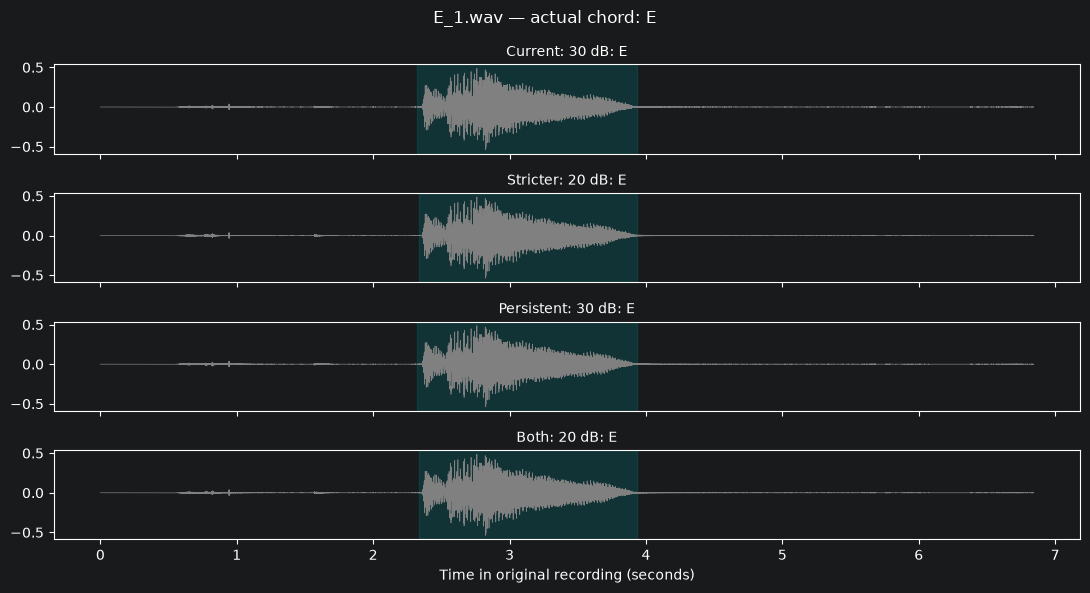

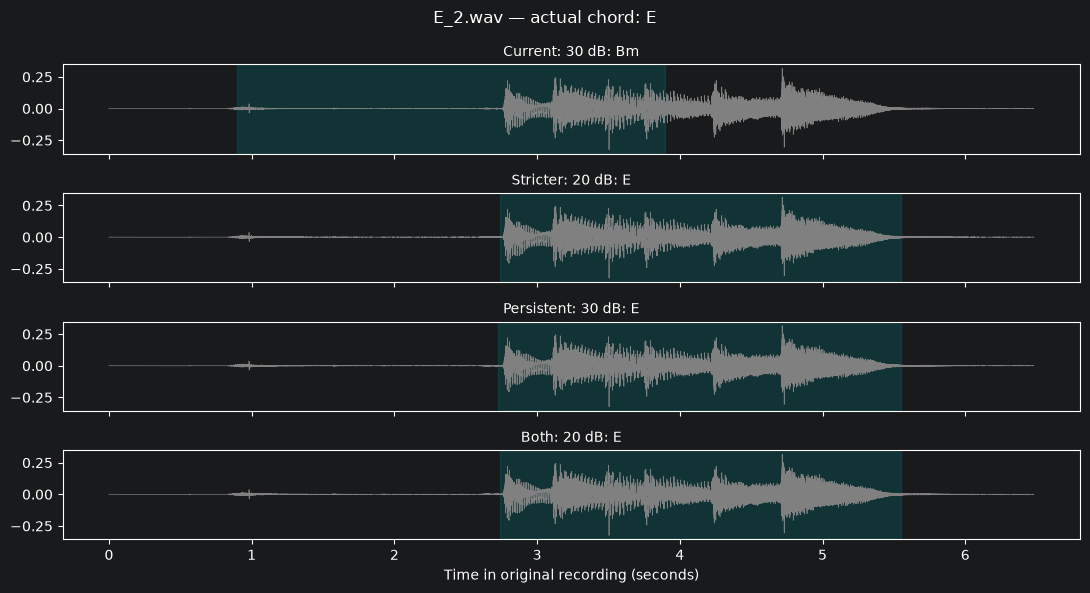

C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1008
  D = stft(
C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1000
  D = stft(
C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1008
  D = stft(
C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1000
  D = stft(


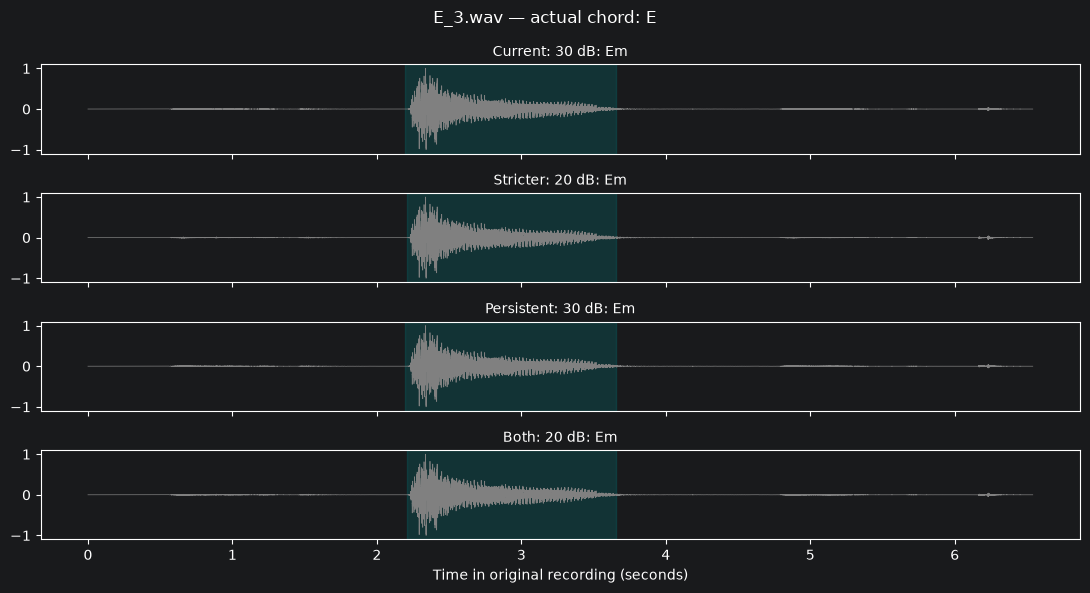

C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1016
  D = stft(
C:\Users\Marcus\Desktop\Coding\university\dat158\obliger\machine_learning\guitar_chord_identifier\.venv\Lib\site-packages\librosa\core\constantq.py:1202: UserWarning: n_fft=1024 is too large for input signal of length=1016
  D = stft(


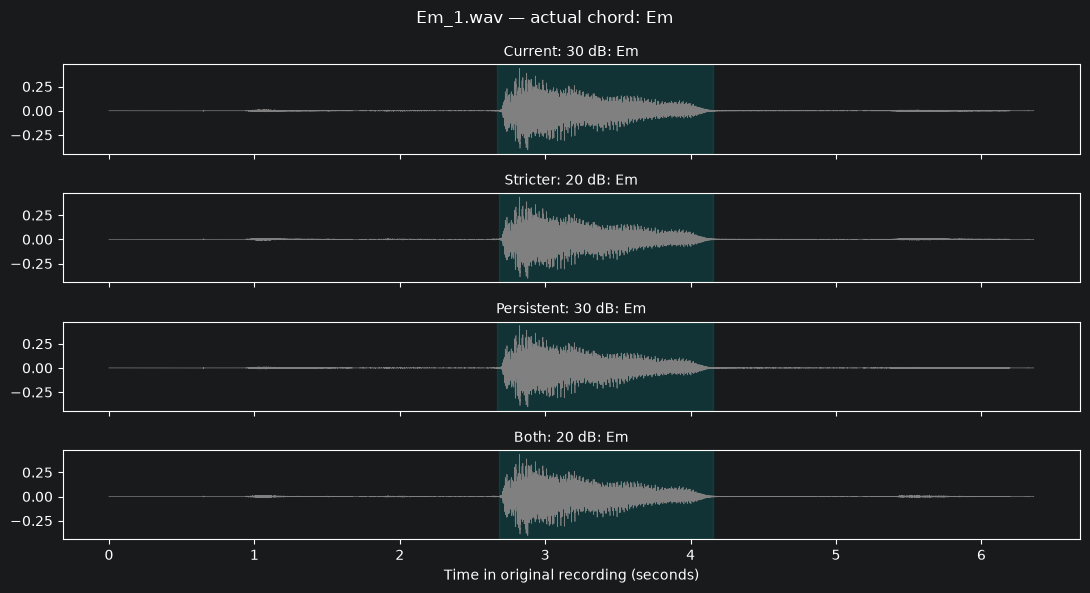

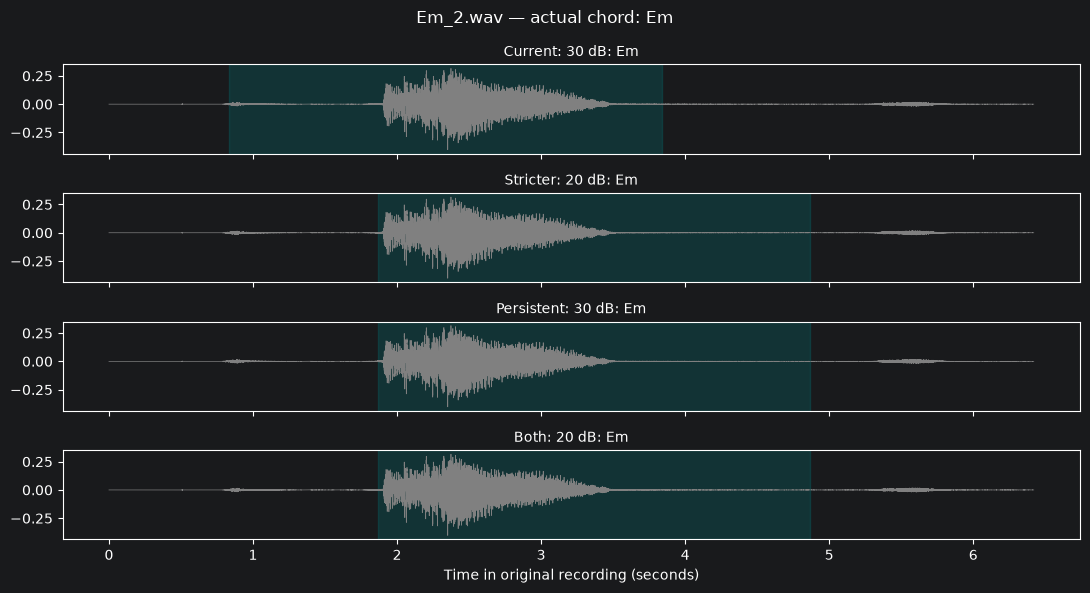

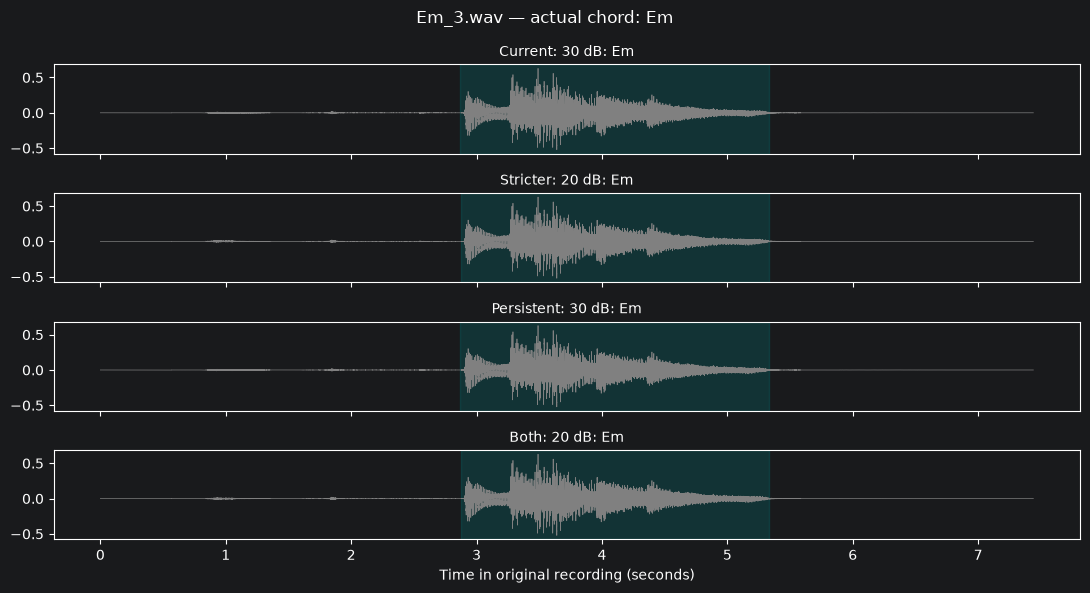

,file,actual,rule,start_s,stop_s,duration_s,prediction,actual_chord_score,correct,note
0,E_1.wav,E,Current: 30 dB,2.322,3.936,1.614,E,0.743,True,Uncalibrated model scores; unfamiliar audio ma...
1,E_1.wav,E,Stricter: 20 dB,2.334,3.936,1.602,E,0.743,True,Uncalibrated model scores; unfamiliar audio ma...
2,E_1.wav,E,Persistent: 30 dB,2.322,3.936,1.614,E,0.743,True,Uncalibrated model scores; unfamiliar audio ma...
3,E_1.wav,E,Both: 20 dB,2.334,3.936,1.602,E,0.743,True,Uncalibrated model scores; unfamiliar audio ma...
4,E_2.wav,E,Current: 30 dB,0.894,3.894,3.000,Bm,0.233,False,Uncalibrated model scores; unfamiliar audio ma...
5,E_2.wav,E,Stricter: 20 dB,2.740,5.550,2.810,E,0.853,True,Uncalibrated model scores; unfamiliar audio ma...
6,E_2.wav,E,Persistent: 30 dB,2.728,5.550,2.821,E,0.853,True,Uncalibrated model scores; unfamiliar audio ma...
7,E_2.wav,E,Both: 20 dB,2.740,5.550,2.810,E,0.853,True,Uncalibrated model scores; unfamiliar audio ma...
8,E_3.wav,E,Current: 30 dB,2.194,3.657,1.463,Em,0.413,False,Uncalibrated model scores; unfamiliar audio ma...
9,E_3.wav,E,Stricter: 20 dB,2.206,3.657,1.451,Em,0.413,False,Uncalibrated model scores; unfamiliar audio ma...


,sum,count
rule,,
Current: 30 dB,4,6
Stricter: 20 dB,5,6
Persistent: 30 dB,5,6
Both: 20 dB,5,6


In [3]:
def compare_files(filepaths, labels):
    rows = []
    for filepath, actual_chord in zip(filepaths, labels):
        original, sr = librosa.load(filepath, sr=sample_rate, mono=True)
        fig, axes = plt.subplots(len(variants), 1, figsize=(11, 6), sharex=True)
        times = np.arange(len(original)) / sr
        for axis, variant in zip(axes, variants):
            axis.plot(times, original, linewidth=0.5, color="gray")
            row = {"file": filepath.name, "actual": actual_chord, "rule": variant}
            try:
                selected, sr, info = experiment_crop(filepath, variant)
                result = predict_window(selected, sr, bundle, require_full=False)
                row.update({
                    "start_s": info["start_s"],
                    "stop_s": info["stop_s"],
                    "duration_s": len(selected) / sr,
                    "prediction": result["prediction"],
                    "actual_chord_score": result["scores"].get(actual_chord, np.nan),
                    "correct": result["prediction"] == actual_chord,
                    "note": result["reason"],
                })
                axis.axvspan(info["start_s"], info["stop_s"], alpha=0.25, color="teal")
                axis.set_title(f"{variant}: {result['prediction']}", fontsize=10)
            except ValueError as error:
                row.update({"prediction": "Rejected", "correct": False, "note": str(error)})
                axis.set_title(f"{variant}: rejected", fontsize=10)
            rows.append(row)
        axes[-1].set_xlabel("Time in original recording (seconds)")
        fig.suptitle(f"{filepath.name} — actual chord: {actual_chord}")
        fig.tight_layout()
        plt.show()
    return pd.DataFrame(rows)

headset_results = compare_files(files, [file.stem.split("_")[0] for file in files])
display(headset_results.round(3))
display(headset_results.groupby("rule", sort=False)["correct"].agg(["sum", "count"]))

## Listen to the selected audio

Change the filename to inspect another recording. All players use the same sample rate and no automatic playback normalisation. Compare what was included, rather than choosing whichever version gives the highest score. Audio is deliberately not embedded in the saved notebook outputs; run this cell locally to hear it.

In [4]:
listen = False  # Change to True to show players locally.
file_to_hear = folder / "E_2.wav"
if listen:
    original, sr = librosa.load(file_to_hear, sr=sample_rate, mono=True)
    print("Original recording")
    display(Audio(original, rate=sr, normalize=False))
    for variant in variants:
        print(variant)
        try:
            selected, sr, info = experiment_crop(file_to_hear, variant)
            display(Audio(selected, rate=sr, normalize=False))
        except ValueError as error:
            print(error)

## Check the trade-off on slow picking

Use the first slow-picking recording of E, Em and G from the phone metadata, chosen without looking at prediction scores. These recordings were used to train the model, so their predictions are not validation results. Here we are checking whether a start rule discards quieter first notes. Listen as well as looking at the waveform; loudness cannot identify individual intended strings.

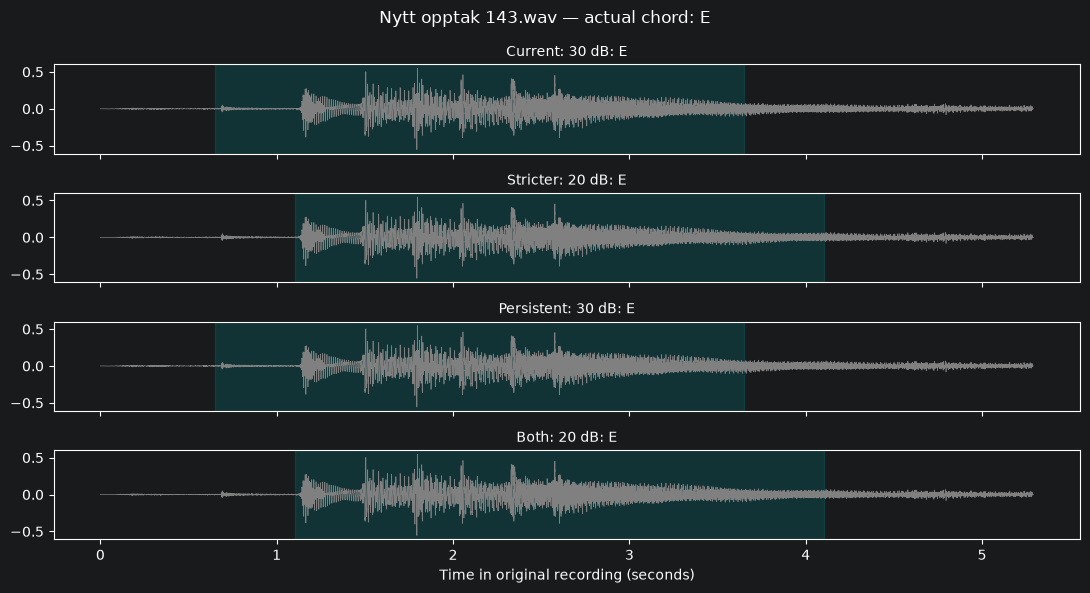

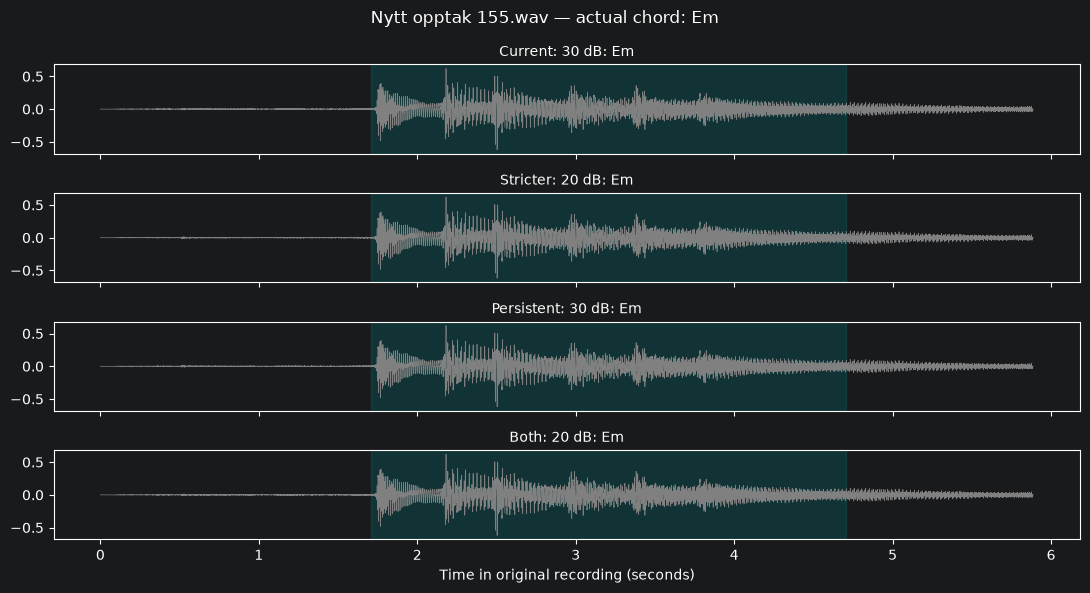

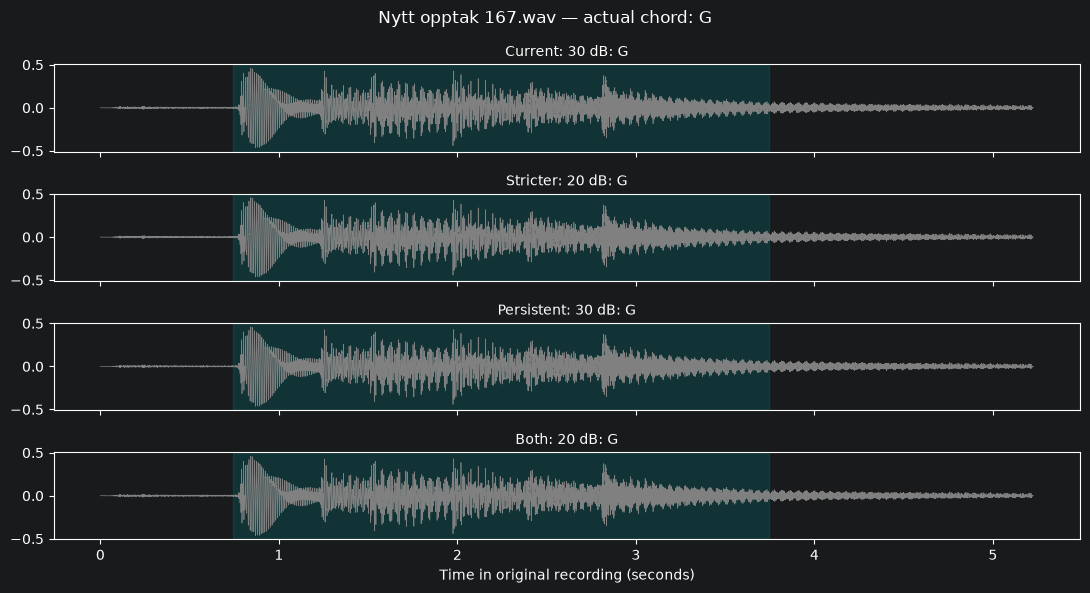

,file,actual,rule,start_s,stop_s,duration_s,prediction,actual_chord_score,correct,note
0,Nytt opptak 143.wav,E,Current: 30 dB,0.650,3.650,3.0,E,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
1,Nytt opptak 143.wav,E,Stricter: 20 dB,1.103,4.103,3.0,E,0.657,True,Uncalibrated model scores; unfamiliar audio ma...
2,Nytt opptak 143.wav,E,Persistent: 30 dB,0.650,3.650,3.0,E,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
3,Nytt opptak 143.wav,E,Both: 20 dB,1.103,4.103,3.0,E,0.657,True,Uncalibrated model scores; unfamiliar audio ma...
4,Nytt opptak 155.wav,Em,Current: 30 dB,1.707,4.707,3.0,Em,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
5,Nytt opptak 155.wav,Em,Stricter: 20 dB,1.707,4.707,3.0,Em,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
6,Nytt opptak 155.wav,Em,Persistent: 30 dB,1.707,4.707,3.0,Em,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
7,Nytt opptak 155.wav,Em,Both: 20 dB,1.707,4.707,3.0,Em,0.923,True,Uncalibrated model scores; unfamiliar audio ma...
8,Nytt opptak 167.wav,G,Current: 30 dB,0.743,3.743,3.0,G,0.920,True,Uncalibrated model scores; unfamiliar audio ma...
9,Nytt opptak 167.wav,G,Stricter: 20 dB,0.743,3.743,3.0,G,0.920,True,Uncalibrated model scores; unfamiliar audio ma...


In [5]:
metadata = pd.read_csv(project_root / "reports/marcus_recordings/metadata.csv")
slow_examples = []
slow_labels = []
for chord in ["E", "Em", "G"]:
    matching = metadata[(metadata["chord"] == chord) &
                        (metadata["technique"] == "slow_picking")]
    row = matching.sort_values("within_chord").iloc[0]
    slow_examples.append(project_root / row["filepath"])
    slow_labels.append(chord)

slow_results = compare_files(slow_examples, slow_labels)
display(slow_results.round(3))
# To listen, set file_to_hear = slow_examples[0] in the player cell above.

## What to decide afterwards

- Did the crop move past the early noise in E_2 and Em_2?
- Did E_3 still get mistaken for Em when its start barely changed?
- Did any rule skip quiet picked notes or reject a usable recording?

Do not choose a setting from these six labels alone. If a rule looks useful, check more playing styles, apply it consistently when rebuilding training features, and evaluate on fresh recordings. The app and saved model remain unchanged.

## Findings from this run

- E_2 started at 0.89 s with the current rule. The alternatives started around 2.73–2.74 s, and E's score rose from 40% to about 86%.
- Em_2 also started later, moving from 0.84 s to 1.87 s. It stayed correctly classified.
- E_3 was still predicted as Em under every rule. Early triggering does not explain that mistake.
- Every rule got 5/6 headset recordings correct. The score changes are not an accuracy improvement.
- On the selected slow-picked E recording, the stricter threshold moved the start from 0.65 s to 1.10 s. Persistence at 30 dB kept the original start. We still need to listen to establish whether the removed sound includes intended notes.

The persistence rule is worth checking on more recordings, but these examples are too few to adopt it yet. No app settings or model files were changed.